BASELINE CNN TRAINING 
- LOAD DATA 
- BUILD MODEL
- TRAIN MODEL
- SAVE MODEL
- PLOT ACCURACY & LOSS 

In [ ]:
# Load the saved files
import numpy as np

X_train = np.load("X_train.npy")
y_train = np.load("y_train.npy")
X_test = np.load("X_test.npy")
y_test = np.load("y_test.npy")

In [2]:
# Build a simple CNN architecture
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(48,48,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(y_train.shape[1], activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

d:\Anaconda\envs\fer_new\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,279 (4.36 MB)

 Trainable params: 1,142,279 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# Train the model
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=64)

Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 33s 42ms/step - accuracy: 0.3000 - loss: 1.7329 - val_accuracy: 0.3828 - val_loss: 1.5794
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.4090 - loss: 1.5278 - val_accuracy: 0.4649 - val_loss: 1.3999
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 19s 43ms/step - accuracy: 0.4564 - loss: 1.4141 - val_accuracy: 0.4933 - val_loss: 1.3089
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.4824 - loss: 1.3527 - val_accuracy: 0.5118 - val_loss: 1.2745
Epoch 5/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.5126 - loss: 1.2880 - val_accuracy: 0.5293 - val_loss: 1.2244
Epoch 6/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.5329 - loss: 1.2366 - val_accuracy: 0.5401 - val_loss: 1.2026
Epoch 7/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.5483 - loss: 1.1870 - val_accuracy: 0.5514 - val_loss: 1.1805
Epoch 8/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.5650 - loss: 1.1423 - 

In [ ]:
import os

os.makedirs("models", exist_ok=True)

model.save("models/emotion_model.keras")

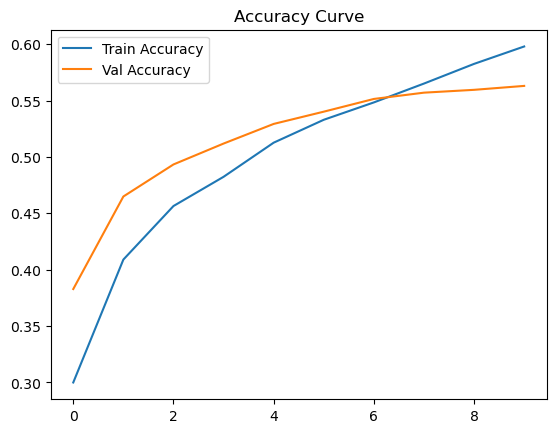

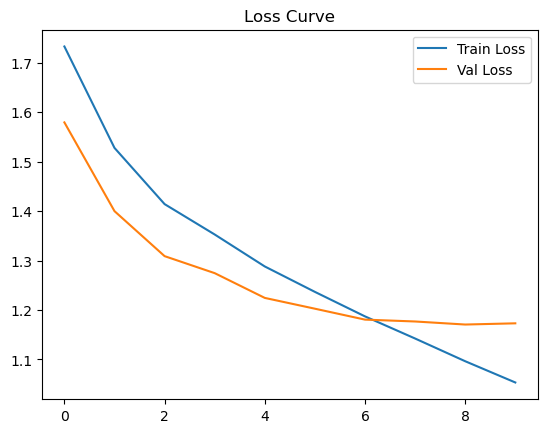

In [8]:
# Plot accuracy & loss curves
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title("Accuracy Curve")
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss Curve")
plt.show()

EVALUATION
- CONFUSION MATRIX
- CLASSIFICATION REPORT

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [12]:
# Predict
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step


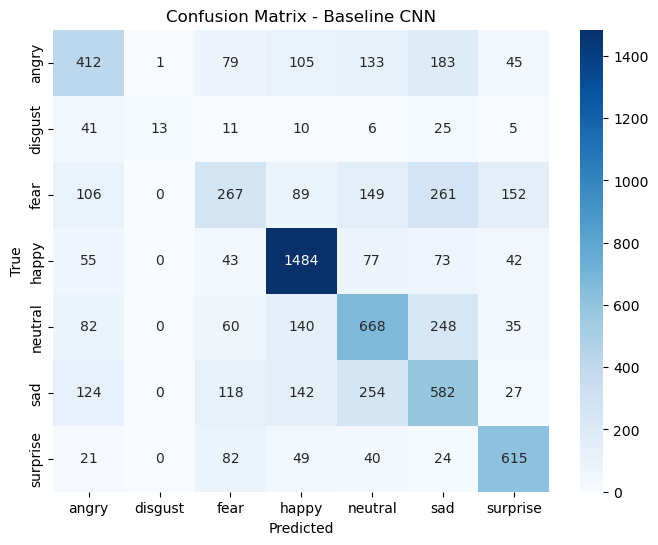

In [13]:
# Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
emotions = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=emotions, yticklabels=emotions)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Baseline CNN")
plt.show()

In [14]:
# Classification Report
print(classification_report(y_true_classes, y_pred_classes, target_names=emotions))

              precision    recall  f1-score   support

       angry       0.49      0.43      0.46       958
     disgust       0.93      0.12      0.21       111
        fear       0.40      0.26      0.32      1024
       happy       0.74      0.84      0.78      1774
     neutral       0.50      0.54      0.52      1233
         sad       0.42      0.47      0.44      1247
    surprise       0.67      0.74      0.70       831

    accuracy                           0.56      7178
   macro avg       0.59      0.48      0.49      7178
weighted avg       0.56      0.56      0.55      7178

